=== Latency Percentiles Comparison (CPU Cycles) ===

--- Activate ---
       Flat  Hierarchical  Diff (H - F)
p50      94            75           -19
p90     108            82           -26
p99     147            97           -50
p99.9   357           234          -123

--- Deactivate ---
       Flat  Hierarchical  Diff (H - F)
p50      93            89            -4
p90     106            98            -8
p99     144           116           -28
p99.9   228           167           -61

--- Get Left Most ---
       Flat  Hierarchical  Diff (H - F)
p50     103            69           -34
p90     118            77           -41
p99     153            90           -63
p99.9   231           116          -115

--- Get Right Most ---
       Flat  Hierarchical  Diff (H - F)
p50     105            71           -34
p90     120            79           -41
p99     155            91           -64
p99.9   232           120          -112

[Baseline Timer Overhead Median: 38 cycles]

Saved overlaid hi

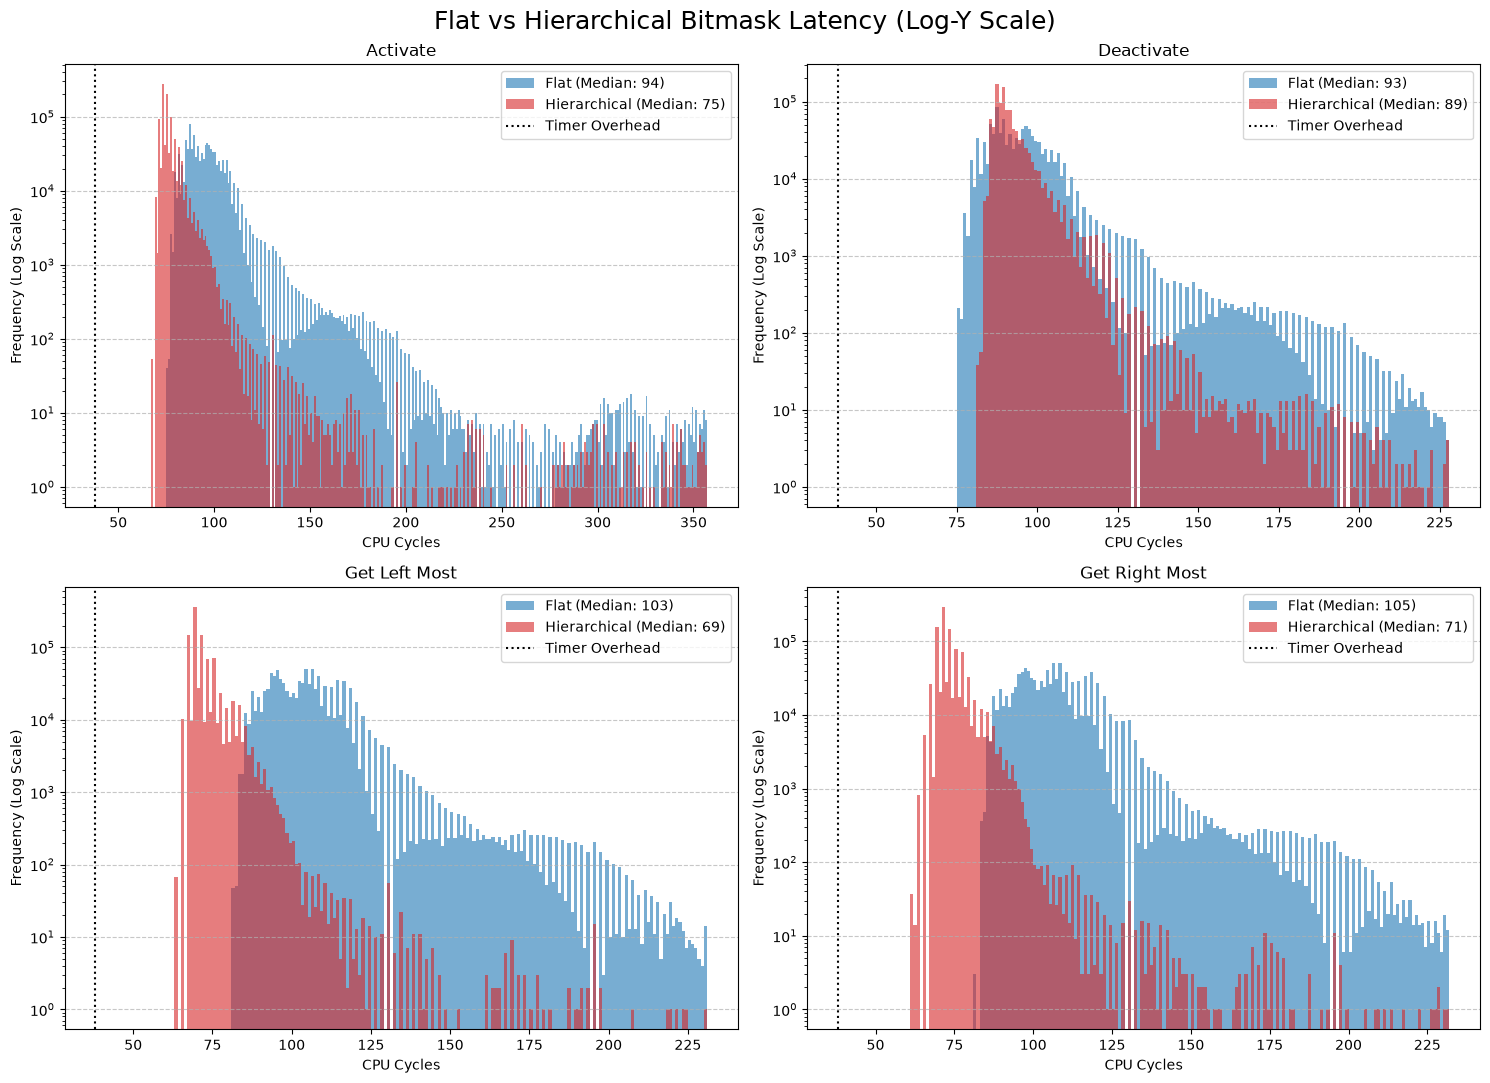

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("comparison_latencies.csv")

operations = ['act', 'deact', 'left', 'right']
op_names = ['Activate', 'Deactivate', 'Get Left Most', 'Get Right Most']

# 1. Print Side-by-Side Percentiles
print("=== Latency Percentiles Comparison (CPU Cycles) ===")
percentiles = [0.50, 0.90, 0.99, 0.999]
stats_idx = [f"p{int(p*100)}" if p < 0.999 else f"p{p*100}" for p in percentiles]

for op, name in zip(operations, op_names):
    print(f"\n--- {name} ---")
    f_stats = df[f"f_{op}"].quantile(percentiles).astype(int)
    h_stats = df[f"h_{op}"].quantile(percentiles).astype(int)
    
    comp_df = pd.DataFrame({
        'Flat': f_stats.values,
        'Hierarchical': h_stats.values,
        'Diff (H - F)': (h_stats.values - f_stats.values)
    }, index=stats_idx)
    print(comp_df.to_string())

baseline_median = int(df['baseline'].median())
print(f"\n[Baseline Timer Overhead Median: {baseline_median} cycles]")
print("===================================================\n")

# 2. Plot Overlaid Histograms
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Flat vs Hierarchical Bitmask Latency (Log-Y Scale)', fontsize=18)

for ax, op, name in zip(axes.flatten(), operations, op_names):
    col_f = f"f_{op}"
    col_h = f"h_{op}"
    
    # Filter extreme outliers for a clean plot using the max 99.9th percentile between both
    max_q999 = max(df[col_f].quantile(0.999), df[col_h].quantile(0.999))
    f_data = df[col_f][df[col_f] < max_q999]
    h_data = df[col_h][df[col_h] < max_q999]
    
    # Define common bins so the bars align perfectly for comparison
    min_val = min(f_data.min(), h_data.min())
    max_val = max(f_data.max(), h_data.max())
    bins = range(int(min_val), int(max_val) + 2) # 1-cycle bin width
    
    # Plot both on the same axis
    ax.hist(f_data, bins=bins, color='#1f77b4', alpha=0.6, label=f'Flat (Median: {int(df[col_f].median())})')
    ax.hist(h_data, bins=bins, color='#d62728', alpha=0.6, label=f'Hierarchical (Median: {int(df[col_h].median())})')
    
    ax.set_title(f'{name}')
    ax.set_xlabel('CPU Cycles')
    ax.set_ylabel('Frequency (Log Scale)')
    ax.set_yscale('log')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Draw baseline timer overhead
    ax.axvline(baseline_median, color='black', linestyle='dotted', linewidth=1.5, label='Timer Overhead')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig("bitmask_comparison_histograms.png", dpi=300, bbox_inches='tight')
print("Saved overlaid histograms to 'bitmask_comparison_histograms.png'")
plt.show()